#  Diabetes Prediction using Logistic Regression

**Student:** Garvit Singh &nbsp;&nbsp;|&nbsp;&nbsp; **Date:** 01 November 2026 &nbsp;&nbsp;|&nbsp;&nbsp; **Dataset:** Pima Indians Diabetes Database (Kaggle, `diabetes.csv`)

**Objective:** Predict `Outcome` → **0 = No diabetes**, **1 = Diabetes**.

**Model:** Median imputation + StandardScaler + balanced Logistic Regression.

**Workflow:** load CSV → inspect data → replace invalid zeros → train-test split → median imputation → scaling → train Logistic Regression → evaluate → interpret coefficients.

**How to run in Google Colab:** Runtime → Run all, and upload `diabetes.csv` when the upload cell asks.

## Step 0: Import libraries and upload the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve, ConfusionMatrixDisplay)

sns.set_style("whitegrid")

In [2]:
# Upload diabetes.csv (works only in Google Colab; elsewhere this is skipped)
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Not running in Colab - using the file already in this folder.")

Not running in Colab - using the file already in this folder.


---
## Step 1: Load the Kaggle CSV and inspect the data

In [3]:
df = pd.read_csv("diabetes.csv")

print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [4]:
# Column names, data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [5]:
# Summary statistics (count, mean, min, max ...)
df.describe().round(2)

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


**Columns (inputs):** Pregnancies, Glucose, BloodPressure, SkinThickness, Insulin, BMI, DiabetesPedigreeFunction, Age.
**Target:** `Outcome` (0 = No diabetes, 1 = Diabetes).

Look at the `min` row above: Glucose, BloodPressure, SkinThickness, Insulin and BMI all have a minimum of **0**. A person cannot have 0 blood pressure or 0 BMI, so these zeros must be missing values in disguise.

Outcome
0    500
1    268
Name: count, dtype: int64

Outcome
0    65.1 %
1    34.9 %
Name: proportion, dtype: str


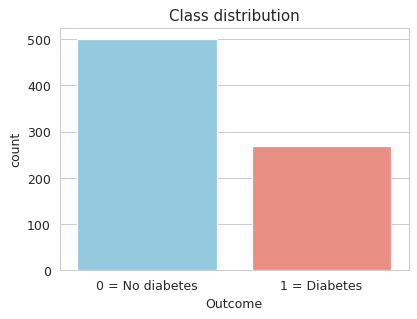

In [6]:
# How balanced is the target?
print(df["Outcome"].value_counts())
print()
print((df["Outcome"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

plt.figure(figsize=(5, 3.5))
sns.countplot(x="Outcome", data=df, palette=["skyblue", "salmon"], hue="Outcome", legend=False)
plt.xticks([0, 1], ["0 = No diabetes", "1 = Diabetes"])
plt.title("Class distribution")
plt.show()

About **65% of people have no diabetes** and **35% have diabetes**. The classes are a little unbalanced, which is why we will use `class_weight="balanced"` in the model, so the model does not simply favour the bigger class.

---
## Step 2: Replace invalid zeros

In [7]:
# These 5 columns cannot be 0 in real life
zero_cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

# Count the invalid zeros in each column
zero_count = (df[zero_cols] == 0).sum()
zero_percent = (zero_count / len(df) * 100).round(1)
pd.DataFrame({"Zeros": zero_count, "Zeros %": zero_percent})

,Zeros,Zeros %
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


In [8]:
# Replace the zeros with NaN (= "missing") so we can fill them properly later
df[zero_cols] = df[zero_cols].replace(0, np.nan)

print("Missing values after replacement:")
df.isnull().sum()

Missing values after replacement:


Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

**Note:** Pregnancies = 0 is perfectly valid (a person may have had no pregnancies), so we leave that column alone.
`Insulin` (~49% missing) and `SkinThickness` (~30% missing) have the most missing data.

---
## Step 3: A quick look at the features (EDA)

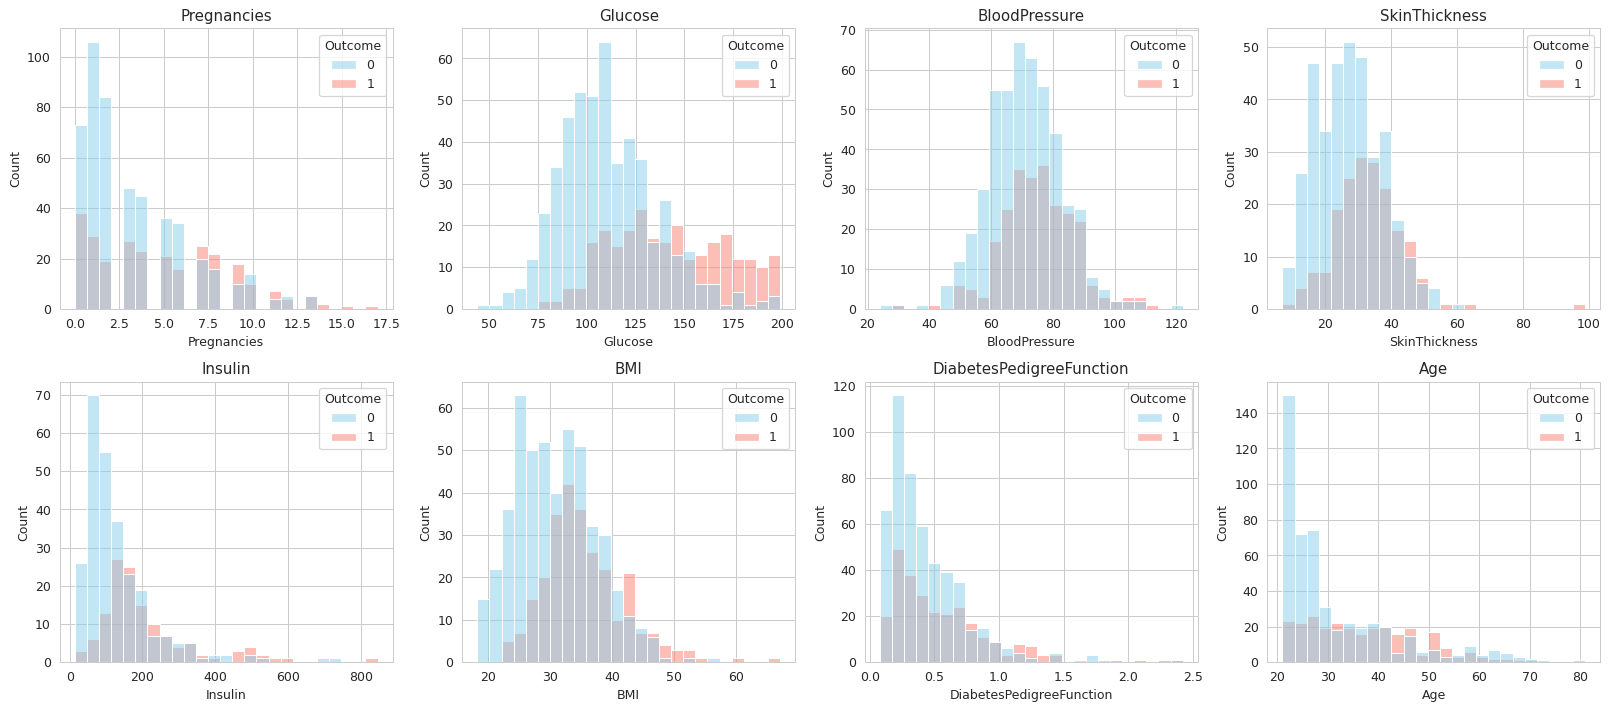

In [9]:
# Distribution of each input feature, split by Outcome
features = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
            "Insulin", "BMI", "DiabetesPedigreeFunction", "Age"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), features):
    sns.histplot(data=df, x=col, hue="Outcome", bins=25, kde=False, ax=ax,
                 palette=["skyblue", "salmon"])
    ax.set_title(col)
plt.tight_layout()
plt.show()

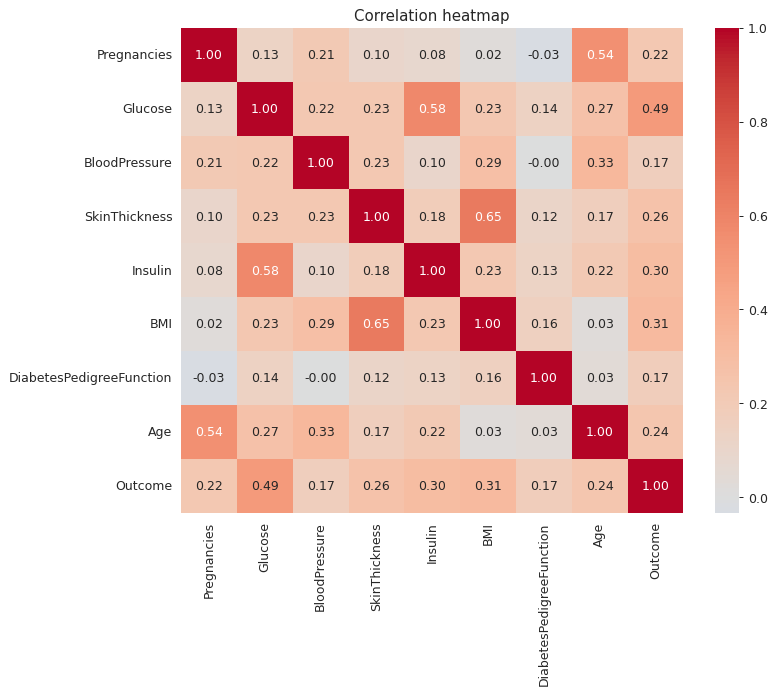

In [10]:
# Correlation heatmap: which features move together with Outcome?
plt.figure(figsize=(9, 7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

**What we see:** people with diabetes (red) tend to have **higher Glucose**, higher BMI and are slightly older. `Glucose` has the strongest correlation with `Outcome`.

---
## Step 4: Train-test split
We split **before** filling missing values or scaling. Otherwise information from the test data would leak into training (called *data leakage*) and the test results would look better than they really are.

In [11]:
X = df.drop(columns="Outcome")    # input features
y = df["Outcome"]                 # target

# 80% train / 20% test. random_state=42 makes the split repeatable.
# stratify=y keeps the 65/35 class ratio the same in both sets.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Training rows:", X_train.shape[0])
print("Testing rows :", X_test.shape[0])
print("\nDiabetes share in train:", round(y_train.mean() * 100, 1), "%")
print("Diabetes share in test :", round(y_test.mean() * 100, 1), "%")

Training rows: 614
Testing rows : 154

Diabetes share in train: 34.9 %
Diabetes share in test : 35.1 %


---
## Step 5: Median imputation
We fill each missing value with the **median** of its column. The median is better than the mean here because columns like Insulin have a few very large values that would drag the mean up.
The medians are learned from the **training data only**, then applied to both sets.

In [12]:
imputer = SimpleImputer(strategy="median")
imputer.fit(X_train)                                  # learn medians from TRAIN only

X_train_imp = imputer.transform(X_train)
X_test_imp = imputer.transform(X_test)

print("Medians used for filling:")
print(pd.Series(imputer.statistics_, index=X.columns).round(2))
print("\nMissing values left in train:", np.isnan(X_train_imp).sum())
print("Missing values left in test :", np.isnan(X_test_imp).sum())

Medians used for filling:
Pregnancies                   3.00
Glucose                     117.00
BloodPressure                72.00
SkinThickness                29.00
Insulin                     125.00
BMI                          32.40
DiabetesPedigreeFunction      0.38
Age                          29.00
dtype: float64

Missing values left in train: 0
Missing values left in test : 0


---
## Step 6: Scaling with StandardScaler
Features are on very different scales (Insulin goes up to ~800, DiabetesPedigreeFunction is below 3). `StandardScaler` rescales every feature to mean = 0 and standard deviation = 1, so that they are comparable and the coefficients can be compared fairly later.

In [13]:
scaler = StandardScaler()
scaler.fit(X_train_imp)                               # learn mean/std from TRAIN only

X_train_scaled = scaler.transform(X_train_imp)
X_test_scaled = scaler.transform(X_test_imp)

# Check: training features should now have mean ~0 and std ~1
print("Mean of scaled train features:", X_train_scaled.mean(axis=0).round(2))
print("Std  of scaled train features:", X_train_scaled.std(axis=0).round(2))

Mean of scaled train features: [-0. -0.  0. -0. -0.  0. -0. -0.]
Std  of scaled train features: [1. 1. 1. 1. 1. 1. 1. 1.]


---
## Step 7: Train the Logistic Regression model
`class_weight="balanced"` gives extra importance to the smaller class (diabetes), so the model pays attention to positive cases instead of mostly predicting "No diabetes".

In [14]:
model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)

print("Model trained!")

Model trained!


---
## Step 8: Evaluate the model on the test set

In [15]:
y_pred = model.predict(X_test_scaled)                    # predicted class (0 or 1)
y_prob = model.predict_proba(X_test_scaled)[:, 1]        # predicted probability of diabetes

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Result": [accuracy, precision, recall, f1, roc_auc],
    "Meaning": ["Overall correct predictions",
                "Reliability of positive predictions",
                "Actual positive cases detected",
                "Balance of precision and recall",
                "Overall class-separation ability"]
})
metrics["Result"] = metrics["Result"].round(3)
metrics

,Metric,Result,Meaning
0,Accuracy,0.734,Overall correct predictions
1,Precision,0.603,Reliability of positive predictions
2,Recall,0.704,Actual positive cases detected
3,F1-score,0.650,Balance of precision and recall
4,ROC-AUC,0.813,Overall class-separation ability


TN = 75  (healthy, predicted healthy)
FP = 25  (healthy, predicted diabetes)
FN = 16  (diabetes, predicted healthy)  <- missed cases
TP = 38  (diabetes, predicted diabetes)


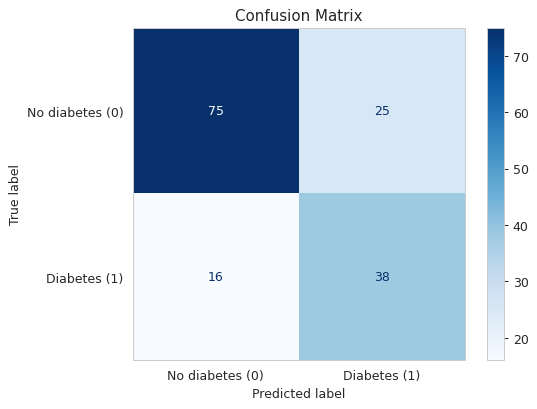

In [16]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn}  (healthy, predicted healthy)")
print(f"FP = {fp}  (healthy, predicted diabetes)")
print(f"FN = {fn}  (diabetes, predicted healthy)  <- missed cases")
print(f"TP = {tp}  (diabetes, predicted diabetes)")

ConfusionMatrixDisplay(cm, display_labels=["No diabetes (0)", "Diabetes (1)"]).plot(cmap="Blues")
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

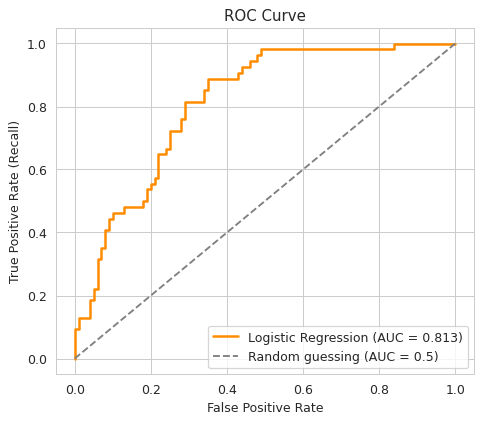

In [17]:
# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="darkorange", lw=2, label=f"Logistic Regression (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Random guessing (AUC = 0.5)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [18]:
# Full report per class
print(classification_report(y_test, y_pred, target_names=["No diabetes (0)", "Diabetes (1)"]))

                 precision    recall  f1-score   support

No diabetes (0)       0.82      0.75      0.79       100
   Diabetes (1)       0.60      0.70      0.65        54

       accuracy                           0.73       154
      macro avg       0.71      0.73      0.72       154
   weighted avg       0.75      0.73      0.74       154


**How to read the results**
- **Accuracy 0.734:** about 73 of every 100 people are classified correctly.
- **Precision 0.603:** when the model says "diabetes", it is right about 60% of the time.
- **Recall 0.704:** the model finds about 70% of the people who really have diabetes.
- **F1-score 0.650:** a single number that balances precision and recall.
- **ROC-AUC 0.813:** if we pick one diabetic and one non-diabetic person at random, the model gives the diabetic a higher risk score about 81% of the time (0.5 = guessing, 1.0 = perfect).
- **Confusion matrix:** 75 + 38 = 113 correct predictions out of 154. The model made 25 false alarms and missed 16 real cases.

Recall matters most in a screening-style task like this, because a **false negative is a missed positive case** (a sick person told they are fine). That is why balanced class weights were used.

---
## Step 9: Interpret the coefficients
Because the features were scaled, a bigger coefficient (in absolute size) means a more influential feature. A **positive** coefficient pushes the prediction towards diabetes, a **negative** one pushes towards no diabetes.

In [19]:
coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_[0].round(3),
    "Odds Ratio": np.exp(model.coef_[0]).round(2)     # exp(coef): change in odds for +1 std of the feature
}).sort_values("Coefficient", ascending=False).reset_index(drop=True)
coef_df

,Feature,Coefficient,Odds Ratio
0,Glucose,1.183,3.27
1,BMI,0.710,2.03
2,Pregnancies,0.373,1.45
3,DiabetesPedigreeFunction,0.288,1.33
4,Age,0.186,1.20
5,SkinThickness,0.014,1.01
6,BloodPressure,-0.015,0.99
7,Insulin,-0.045,0.96


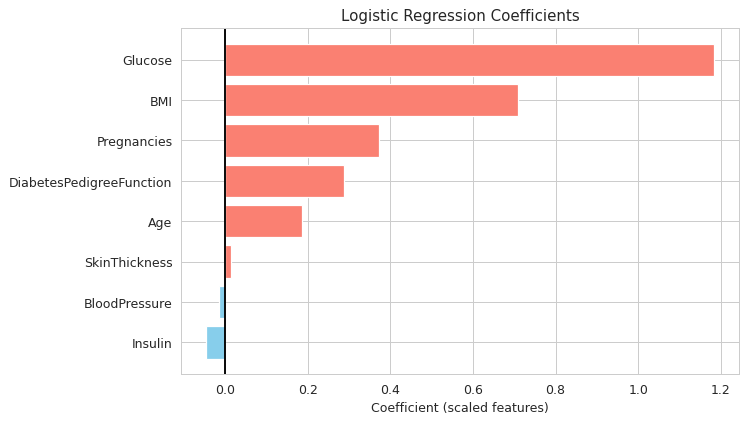

In [20]:
plt.figure(figsize=(8, 5))
colors = ["salmon" if c > 0 else "skyblue" for c in coef_df["Coefficient"]]
plt.barh(coef_df["Feature"], coef_df["Coefficient"], color=colors)
plt.axvline(0, color="black")
plt.gca().invert_yaxis()
plt.xlabel("Coefficient (scaled features)")
plt.title("Logistic Regression Coefficients")
plt.show()

**Interpretation:**
- **Glucose** (coefficient ≈ 1.18) is by far the strongest factor. One standard deviation higher glucose multiplies the odds of diabetes by about 3.3.
- **BMI** (≈ 0.71) is second: higher body mass index raises the odds (about 2.0×).
- **Pregnancies**, **DiabetesPedigreeFunction** and **Age** have smaller positive effects.
- **BloodPressure**, **SkinThickness** and **Insulin** have coefficients close to zero, so they add little once the other features are known. (Insulin and SkinThickness also had the most missing values that we had to fill.)

---
## Final Conclusion

In this project I built a Logistic Regression model on the Pima Indians Diabetes data to predict whether a person has diabetes. First I found that columns like Glucose, BMI and Insulin had zeros that cannot be real, so I treated them as missing, split the data, and filled them with the median of the training set. After scaling the features I trained a balanced Logistic Regression.

On the test set the model reached an **accuracy of 73.4%**, a **ROC-AUC of 0.813** and a **recall of 70.4%**, so it finds about 7 out of every 10 people who actually have diabetes. Its precision is lower (60.3%), which means that roughly 4 out of 10 "diabetes" predictions are false alarms. For a screening-style task I think this trade-off is acceptable, because missing a sick person (16 cases here) is worse than sending a healthy person for another check (25 cases).

**Glucose** and **BMI** were the most important factors for the prediction, which makes sense medically too.

**Limitations:** the dataset is small (768 people) and comes from one specific population, so the model may not work for other groups. Almost half of the Insulin values were missing, which adds uncertainty. This model is good for learning classification concepts, **not for real medical diagnosis**.